# 15 - BalancingData

In [4]:
import pandas as pd
import numpy as np

In [5]:
#np.random seed
#np.random.seed rastgele olustururken algoritmaya göre olusturuyor.
#tekrar rastagele olusuturuldugunda donanımlı birş ey için
#tutarlı değerler için
np.random.seed(42)
set1no = 900
set2no = 100

In [11]:
df1 = pd.DataFrame({
    "feature_1": np.random.normal(loc=0, scale=1, size=set1no),
    "feature_2": np.random.normal(loc=0, scale=1, size=set1no),
    "target": [0] * set1no,
})

df2 = pd.DataFrame({
    "feature_1": np.random.normal(loc=0, scale=1, size=set2no),
    "feature_2": np.random.normal(loc=0, scale=1, size=set2no),
    "target": [1] * set2no,
})

In [13]:
df1.head()

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0


In [14]:
df2.head()

,feature_1,feature_2,target
0,0.933810,0.934655,1
1,0.503232,0.369926,1
2,2.305637,-1.117327,1
3,-1.015581,-0.041491,1
4,0.822573,0.970488,1


In [16]:
df = pd.concat([df1,df2]).reset_index(drop=True)

In [17]:
df

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0
...,...,...,...
995,-0.778309,1.301102,1
996,-0.443429,-1.998345,1
997,-0.270270,-0.705317,1
998,1.612868,0.495766,1


In [18]:
df["target"].unique()

array([0, 1])

In [19]:
df["target"].value_counts()

target
0    900
1    100
Name: count, dtype: int64

In [ ]:
#upsampling - 1 leri arttırmak azınlıgı arttırmak

In [ ]:
#downsampling -> 1 leri 900 e çıkartmak 0 ları 100 e indirmek.
#çopunlugu azaltmak

In [ ]:
#diyelim kı cok datamız var downsamplıng yaptıgmızda 
#900 tane olan sıfırıdn 800 ünü yalan etmektir. baya azaltmaktır.
#zaten az ise datamız dezavantaj veriyor bize. 
#her zaman tercih edilmeyebilir.
#upsampling daha cok terchi ediliyor. bellirli algoritma dahilinde.


In [20]:
#upsampling

In [23]:
df_minority = df[df["target"] == 1]

In [24]:
#içeisinde sadece 1 olan azınlıklarımız var
df_minority

,feature_1,feature_2,target
900,0.933810,0.934655,1
901,0.503232,0.369926,1
902,2.305637,-1.117327,1
903,-1.015581,-0.041491,1
904,0.822573,0.970488,1
...,...,...,...
995,-0.778309,1.301102,1
996,-0.443429,-1.998345,1
997,-0.270270,-0.705317,1
998,1.612868,0.495766,1


In [25]:
df_majority = df[df["target"] == 0]

In [26]:
#sadece 0 olanlar
df_majority

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0
...,...,...,...
895,2.045655,1.245041,0
896,0.530343,-0.051509,0
897,0.304492,0.375360,0
898,-1.057515,-0.115188,0


In [27]:
#ml de çok kullanılıyor.her yerde karsımıza cıkar.
#acayip fazla özellıgı var.
from sklearn.utils import resample

In [29]:
df_minority_upsamled= resample(df_minority,replace=True,n_samples=len(df_majority),random_state=42)

In [30]:
df_minority_upsamled

,feature_1,feature_2,target
951,-0.156276,0.227405,1
992,-0.363176,0.662169,1
914,-0.133279,0.654388,1
971,-1.227829,0.701390,1
960,0.605405,-1.070666,1
...,...,...,...
952,0.686774,-0.889845,1
965,-0.029766,0.501129,1
976,1.896123,1.674271,1
942,-0.547192,2.022174,1


In [31]:
df_upsampled = pd.concat([df_majority,df_minority_upsamled])

In [32]:
df_upsampled

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0
...,...,...,...
952,0.686774,-0.889845,1
965,-0.029766,0.501129,1
976,1.896123,1.674271,1
942,-0.547192,2.022174,1


In [34]:
df_upsampled["target"].value_counts()

target
0    900
1    900
Name: count, dtype: int64

In [36]:
df_majority_downsampled= resample(df_majority,replace=True,n_samples=len(df_minority),random_state=42)

In [37]:
df_majority_downsampled

,feature_1,feature_2,target
102,-0.480574,0.498690,0
435,0.150474,-0.187330,0
860,0.295933,-1.419433,0
270,-1.476657,-1.098679,0
106,-0.038324,-0.202606,0
...,...,...,...
201,1.236832,1.021963,0
269,0.792711,0.342226,0
862,-0.425818,0.198217,0
815,0.065738,-0.066166,0


In [38]:
df_majority_downsampled["target"].value_counts()

target
0    100
Name: count, dtype: int64

In [39]:
df_downsampled = pd.concat([df_majority_downsampled,df_minority])

In [40]:
df_downsampled

,feature_1,feature_2,target
102,-0.480574,0.498690,0
435,0.150474,-0.187330,0
860,0.295933,-1.419433,0
270,-1.476657,-1.098679,0
106,-0.038324,-0.202606,0
...,...,...,...
995,-0.778309,1.301102,1
996,-0.443429,-1.998345,1
997,-0.270270,-0.705317,1
998,1.612868,0.495766,1


In [42]:
df_downsampled["target"].value_counts()

target
0    100
1    100
Name: count, dtype: int64

## SMOTE (Synthetic Minority Over-sampling Technique)
### Benzer dataları olusturarak tekrar ettirir. Daha cok kullanılır.

In [43]:
df

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0
...,...,...,...
995,-0.778309,1.301102,1
996,-0.443429,-1.998345,1
997,-0.270270,-0.705317,1
998,1.612868,0.495766,1


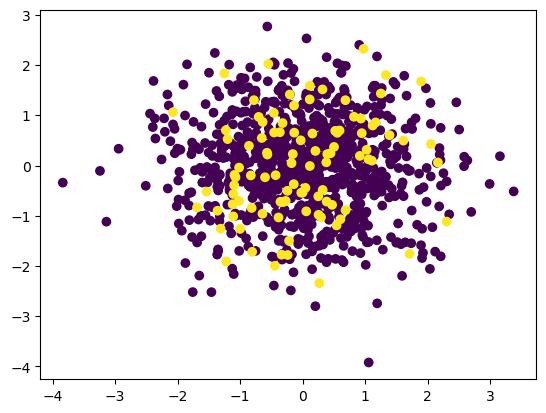

In [46]:
import matplotlib.pyplot as plt
plt.scatter(df["feature_1"],df["feature_2"],c=df["target"])

In [47]:
#imbalanced - düzenlemek için kullanılan kütüpjane
!pip install imblearn

In [48]:
from imblearn.over_sampling import SMOTE

In [49]:
oversample = SMOTE()

In [51]:
(X,y) = oversample.fit_resample(df[["feature_1","feature_2"]],df["target"])

In [50]:
#(X,y)  y= target hedeflediğimiz şeydir. x=feature

In [52]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1795    1
1796    1
1797    1
1798    1
1799    1
Name: target, Length: 1800, dtype: int64

In [53]:
X

,feature_1,feature_2
0,-0.033025,-0.116571
1,-0.503650,0.214169
2,-0.172375,-0.976620
3,0.714732,0.160269
4,1.277857,-0.423834
...,...,...
1795,-0.066701,-0.458109
1796,-0.372655,-1.923629
1797,-0.368474,-0.869879
1798,0.534366,-1.061265


In [54]:
type(X)

pandas.core.frame.DataFrame

In [55]:
oversample_df = pd.concat([X,y],axis=1)

In [56]:
oversample_df

,feature_1,feature_2,target
0,-0.033025,-0.116571,0
1,-0.503650,0.214169,0
2,-0.172375,-0.976620,0
3,0.714732,0.160269,0
4,1.277857,-0.423834,0
...,...,...,...
1795,-0.066701,-0.458109,1
1796,-0.372655,-1.923629,1
1797,-0.368474,-0.869879,1
1798,0.534366,-1.061265,1


In [57]:
oversample_df["target"].value_counts()

target
0    900
1    900
Name: count, dtype: int64

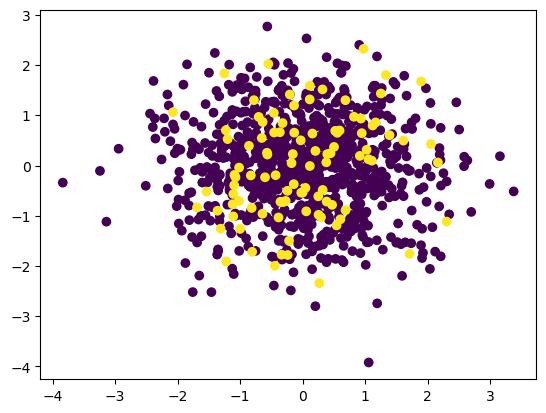

In [58]:
plt.scatter(df["feature_1"],df["feature_2"],c=df["target"])

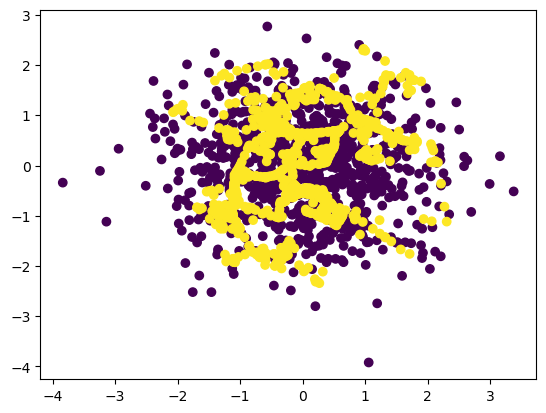

In [60]:
plt.scatter(oversample_df["feature_1"],oversample_df["feature_2"],c=oversample_df["target"])